# VALORA AI — Complete Modeling Comparison
### Professor's `02_modelling` structure | All models in one notebook

This notebook follows the same **12 sections** as the five original modeling notebooks. It compares all models using the **same cleaned real-apartment dataset and the same train/test split**. The goal is to predict *advertised asking prices*, not verified transaction prices.

**Models:** Mean-price baseline, Linear Regression, Random Forest, Random Forest with Feature Engineering, Optimized Random Forest, and Extra Trees.

**Instructions:** Run all cells in order. When asked, upload `valora_cleaned_step2(2).csv` (or `valora_cleaned_step2.csv`). All explanations are in English.

## 1. TL;DR
I compare several regression algorithms to identify which one predicts apartment asking prices most accurately. I use MAE, RMSE, and R² and examine the largest errors. The model with the lowest MAE is not automatically suitable for professional valuation.

## 2. Recap of the goal
**Business problem:** Estimate advertised asking prices for apartments in Montenegro from their area, bedrooms, and city.

**Target:** `price_eur`  
**Input features:** apartment area (`area_m2`), bedrooms (`sobe`), and city (`city_clean`).  
**Scope:** Real online apartment listings only; exclude simulated records and appraisal records.

**Fair comparison:** One fixed 80/20 split is shared by all algorithms. Hyperparameter tuning uses only training folds. Results from a different dataset or price-limited subset must not be compared as if they used the same test set.

## 3. Setup & data loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from pathlib import Path

paths = [Path('valora_cleaned_step2(2).csv'), Path('valora_cleaned_step2.csv')]
path = next((p for p in paths if p.exists()), None)
if path is None:
    from google.colab import files
    uploaded = files.upload()
    path = Path(next((name for name in uploaded if name.lower().endswith('.csv')), ''))
if not path.is_file():
    raise FileNotFoundError('Upload the cleaned VALORA CSV file.')
df = pd.read_csv(path, low_memory=False)
print('Loaded:', path.name, '| Original shape:', df.shape)

required = ['property_type_clean','data_origin','data_source','price_eur','area_m2','sobe','city_clean']
missing = [c for c in required if c not in df.columns]
if missing: raise ValueError('Missing required columns: ' + str(missing))
real = df.loc[
    df['property_type_clean'].astype(str).str.strip().str.lower().eq('apartment') &
    df['data_origin'].astype(str).str.strip().str.upper().eq('REAL') &
    df['data_source'].astype(str).str.strip().eq('Online listing')
].copy()
real['price_eur'] = pd.to_numeric(real['price_eur'],errors='coerce')
real['area_m2'] = pd.to_numeric(real['area_m2'],errors='coerce')
real['bedrooms'] = pd.to_numeric(real['sobe'],errors='coerce')
real['city_model'] = real['city_clean'].fillna('Unknown').astype(str).str.strip().replace('', 'Unknown')
real['price_per_m2_check'] = real['price_eur']/real['area_m2'].replace(0,np.nan)
review_flags = real.loc[
    (real['price_eur'] < 10000) | (real['area_m2'] < 10) |
    (real['area_m2'] > 1000) | (real['price_per_m2_check'] < 300) |
    (real['price_per_m2_check'] > 15000)
].copy()
clean = real.loc[
    (real['price_eur'] > 0) & (real['area_m2'] > 0) &
    np.isfinite(real['price_eur']) & np.isfinite(real['area_m2'])
].copy()
print('Real apartment listings:',len(real),'| Usable:',len(clean),'| Review flags:',len(review_flags))
print('Unknown city count:',clean['city_model'].eq('Unknown').sum())

Loaded: valora_cleaned_step2.csv | Original shape: (4036, 48)
Real apartment listings: 1473 | Usable: 1473 | Review flags: 37
Unknown city count: 703


## 4. Feature preparation

In [3]:
def add_features(frame):
    out = frame.copy()
    out['area_squared'] = out['area_m2']**2
    out['area_per_bedroom'] = out['area_m2']/out['bedrooms'].replace(0,np.nan)
    out['size_group'] = pd.cut(out['area_m2'],[0,50,100,np.inf],
        labels=['Small','Medium','Large']).astype('object').fillna('Unknown')
    return out

basic_num = ['area_m2','bedrooms']
basic_cat = ['city_model']
advanced_num = ['area_m2','bedrooms','area_squared','area_per_bedroom']
advanced_cat = ['city_model','size_group']

def processor(advanced=False):
    return ColumnTransformer([
        ('numeric',SimpleImputer(strategy='median'),advanced_num if advanced else basic_num),
        ('categorical',OneHotEncoder(handle_unknown='ignore'),advanced_cat if advanced else basic_cat)
    ])
print('Basic:',basic_num+basic_cat)
print('Engineered:',advanced_num+advanced_cat)

Basic: ['area_m2', 'bedrooms', 'city_model']
Engineered: ['area_m2', 'bedrooms', 'area_squared', 'area_per_bedroom', 'city_model', 'size_group']


## 5. Train/test split

In [4]:
X = clean[['area_m2','bedrooms','city_model']].copy()
y = clean['price_eur'].copy()
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train_advanced = add_features(X_train)
X_test_advanced = add_features(X_test)
print('Train:',len(X_train),'| Test:',len(X_test))

Train: 1178 | Test: 295


## 6. Baseline model

In [5]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train,y_train)
predictions = {'Mean-price baseline':baseline.predict(X_test)}
print('Baseline test MAE: €{:,.0f}'.format(mean_absolute_error(y_test,predictions['Mean-price baseline'])))

Baseline test MAE: €107,905


## 7. Candidate models
The models below reproduce the algorithm families used in my five modeling notebooks. The optimized Random Forest searches its settings with **training-only cross-validation**. Each model uses exactly the same held-out test apartments.

The baseline and Linear Regression use basic features; engineered variants use squared area, area per bedroom, and size group.

In [6]:
models = {
    'Linear Regression': (Pipeline([('preprocess',processor(False)),
                                   ('model',LinearRegression())]), False),
    'Random Forest': (Pipeline([('preprocess',processor(False)),
                               ('model',RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1))]), False),
    'Random Forest + Features': (Pipeline([('preprocess',processor(True)),
                               ('model',RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1))]), True),
    'Extra Trees': (Pipeline([('preprocess',processor(True)),
                               ('model',ExtraTreesRegressor(n_estimators=100,random_state=42,n_jobs=-1))]), True)
}
fitted = {}
for name,(estimator,advanced) in models.items():
    train = X_train_advanced if advanced else X_train
    test = X_test_advanced if advanced else X_test
    estimator.fit(train,y_train)
    fitted[name] = (estimator,advanced)
    predictions[name] = estimator.predict(test)
    print('Trained:',name)

optimized = Pipeline([('preprocess',processor(True)),
                      ('model',RandomForestRegressor(random_state=42,n_jobs=-1))])
search = GridSearchCV(optimized,{
    'model__n_estimators':[100,150],
    'model__min_samples_leaf':[2,4,6],
    'model__max_depth':[None,15]
},cv=KFold(3,shuffle=True,random_state=42),
    scoring='neg_mean_absolute_error',n_jobs=1)
search.fit(X_train_advanced,y_train)
fitted['Optimized Random Forest'] = (search.best_estimator_,True)
predictions['Optimized Random Forest'] = search.predict(X_test_advanced)
print('Best optimized RF settings:',search.best_params_)
print('Training cross-validation MAE: €{:,.0f}'.format(-search.best_score_))

Trained: Linear Regression
Trained: Random Forest
Trained: Random Forest + Features
Trained: Extra Trees
Best optimized RF settings: {'model__max_depth': 15, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
Training cross-validation MAE: €63,468


## 8. Evaluation & comparison

,Model,MAE (EUR),RMSE (EUR),R2
0,Linear Regression,68637.18,125649.86,0.49
1,Optimized Random Forest,71179.04,136275.97,0.40
2,Random Forest + Features,72936.40,141012.86,0.36
3,Random Forest,73161.70,144400.79,0.33
4,Extra Trees,74588.21,153998.11,0.24
5,Mean-price baseline,107905.02,176181.71,-0.00


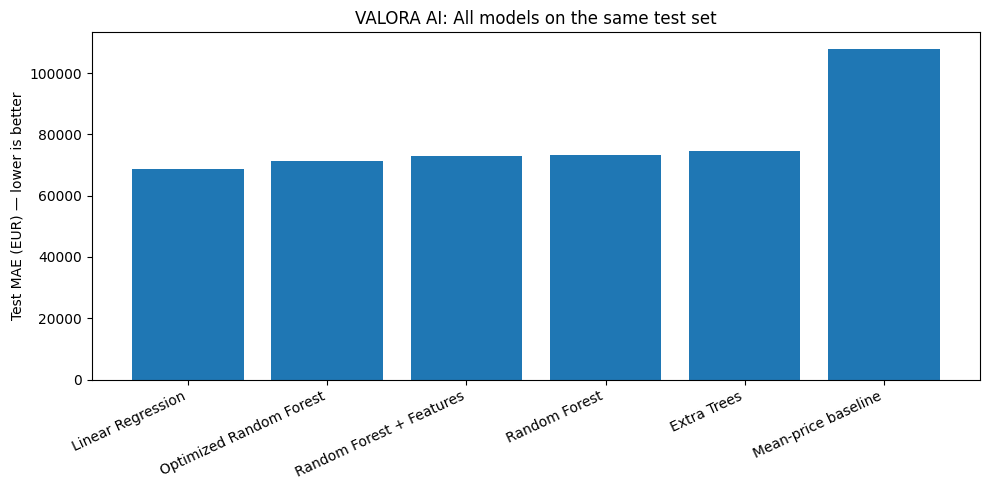

Lowest test MAE: Linear Regression
Note: The test set is for reporting, not repeated hyperparameter selection.


In [7]:
def scores(name,pred):
    return {'Model':name,
            'MAE (EUR)':mean_absolute_error(y_test,pred),
            'RMSE (EUR)':np.sqrt(mean_squared_error(y_test,pred)),
            'R2':r2_score(y_test,pred)}
results = pd.DataFrame([scores(name,pred) for name,pred in predictions.items()])
results = results.sort_values('MAE (EUR)').reset_index(drop=True)
display(results.round(2))
plt.figure(figsize=(10,5))
plt.bar(results['Model'],results['MAE (EUR)'])
plt.ylabel('Test MAE (EUR) — lower is better')
plt.title('VALORA AI: All models on the same test set')
plt.xticks(rotation=25,ha='right')
plt.tight_layout()
plt.show()
winner_name = results.iloc[0]['Model']
print('Lowest test MAE:',winner_name)
print('Note: The test set is for reporting, not repeated hyperparameter selection.')

## 9. Error analysis
Compare errors across asking-price bands and cities. Extreme-price listings and unknown locations can produce especially large errors. These are **advertised** asking prices.

Ten largest errors for: Extra Trees


,area_m2,bedrooms,city_model,actual_eur,predicted_eur,absolute_error_eur,absolute_pct_error,price_band
110,164.0,2.0,Unknown,312500.0,1.700910e+06,1.388410e+06,444.291200,300–500k
1293,100.0,2.0,Unknown,1300000.0,2.829455e+05,1.017054e+06,78.234962,Over 1m
151,140.0,2.0,Unknown,1450000.0,7.216667e+05,7.283333e+05,50.229885,Over 1m
365,107.0,2.0,Tivat,949000.0,3.783567e+05,5.706433e+05,60.131015,500k–1m
1433,99.0,NaN,Unknown,199000.0,7.679200e+05,5.689200e+05,285.889447,100–200k
1431,99.0,NaN,Unknown,255000.0,7.679200e+05,5.129200e+05,201.145098,200–300k
124,88.0,1.0,Unknown,299000.0,7.875000e+05,4.885000e+05,163.377926,200–300k
303,120.0,2.0,Unknown,235000.0,6.500000e+05,4.150000e+05,176.595745,200–300k
1252,80.0,1.0,Unknown,770000.0,3.777125e+05,3.922875e+05,50.946431,500k–1m
1294,47.0,NaN,Unknown,395000.0,8.190000e+04,3.131000e+05,79.265823,300–500k


Error by asking-price band:


,count,mean
price_band,,
Under 100k,35,69842.0
100–200k,151,31219.0
200–300k,64,87117.0
300–500k,31,154574.0
500k–1m,12,227689.0
Over 1m,2,872694.0


Error by city:


,count,mean
city_model,,
Unknown,146,111234.0
Podgorica,96,27872.0
Ulcinj,14,37098.0
Tivat,11,122243.0
Kolasin,10,48648.0
Bar,7,52084.0
Budva,4,45177.0
Zabljak,3,15057.0
Kotor,2,51341.0


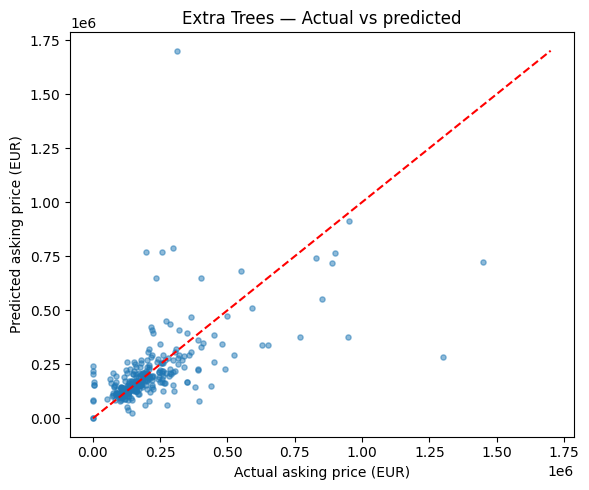

In [8]:
# For a fixed, interpretable analysis, inspect Extra Trees if present.
analysis_name = 'Extra Trees'
pred = predictions[analysis_name]
errors = X_test.copy()
errors['actual_eur'] = y_test
errors['predicted_eur'] = pred
errors['absolute_error_eur'] = abs(errors['actual_eur']-errors['predicted_eur'])
errors['absolute_pct_error'] = 100*errors['absolute_error_eur']/errors['actual_eur']
errors['price_band'] = pd.cut(errors['actual_eur'],
    [0,100000,200000,300000,500000,1000000,np.inf],
    labels=['Under 100k','100–200k','200–300k','300–500k','500k–1m','Over 1m'])
print('Ten largest errors for:',analysis_name)
display(errors.nlargest(10,'absolute_error_eur'))
print('Error by asking-price band:')
display(errors.groupby('price_band',observed=True)['absolute_error_eur'].agg(['count','mean']).round(0))
print('Error by city:')
display(errors.groupby('city_model')['absolute_error_eur'].agg(['count','mean'])
        .sort_values('count',ascending=False).head(12).round(0))
plt.figure(figsize=(6,5))
plt.scatter(y_test,pred,alpha=.5,s=14)
limit=max(float(y_test.max()),float(np.max(pred)))
plt.plot([0,limit],[0,limit],'r--')
plt.xlabel('Actual asking price (EUR)')
plt.ylabel('Predicted asking price (EUR)')
plt.title('Extra Trees — Actual vs predicted')
plt.tight_layout()
plt.show()

## 10. Interpretation

,MAE increase after shuffling (EUR)
size_group,11456.61
city_model,10147.30
area_squared,1216.07
area_m2,-9.26
bedrooms,-152.68
area_per_bedroom,-6108.22


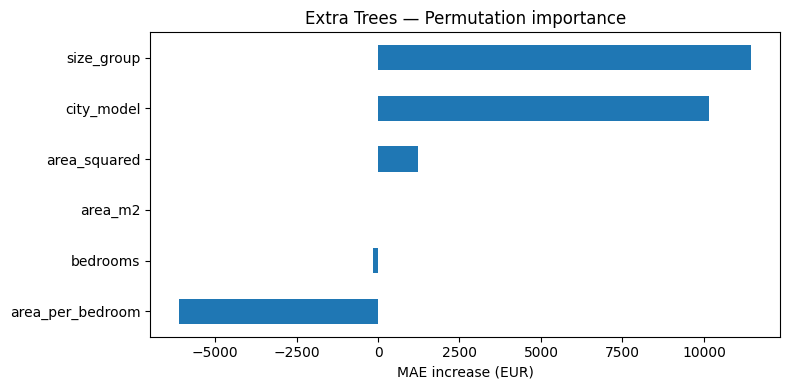

In [9]:
estimator,advanced = fitted['Extra Trees']
test = X_test_advanced if advanced else X_test
importance = permutation_importance(estimator,test,y_test,n_repeats=3,
                                     random_state=42,scoring='neg_mean_absolute_error')
imp = pd.Series(importance.importances_mean,index=test.columns).sort_values(ascending=False)
display(imp.to_frame('MAE increase after shuffling (EUR)').round(2))
plt.figure(figsize=(8,4))
imp.sort_values().plot.barh()
plt.xlabel('MAE increase (EUR)')
plt.title('Extra Trees — Permutation importance')
plt.tight_layout()
plt.show()

## 11. Limitations & ethics
- Online listing prices are **not** verified sale prices or certified appraisals.
- City-level location is coarse; neighborhood, condition, sea view, floor, and building quality are often missing.
- Unknown city values and luxury apartments may have very large errors.
- Excluding properties above €300,000 changes the prediction population; it does not prove an algorithm has improved.
- The original notebooks and earlier development already examined test data. The scores here are **exploratory**, not a guarantee of future accuracy. A fresh independent dataset is needed for a final unbiased assessment.
- Do not use the output as the sole basis for a financial decision.

## 12. Conclusion & next steps
I compared a mean-price baseline with Linear Regression, Random Forest, Random Forest with Feature Engineering, Optimized Random Forest, and Extra Trees. I used the same training and test split and evaluated MAE, RMSE, and R².

**Next steps:** improve city recovery and listing quality, collect neighborhood and property-condition features, and evaluate on genuinely new listings. A separate standard-apartment model (up to €300,000) can be developed and evaluated as a clearly defined second use case.

In [10]:
# Save comparison reports after running the notebook.
results.to_csv('VALORA_ALL_MODELS_COMPARISON.csv',index=False)
errors.to_csv('VALORA_EXTRA_TREES_ERRORS.csv',index=True)
print('Saved VALORA_ALL_MODELS_COMPARISON.csv and VALORA_EXTRA_TREES_ERRORS.csv')

Saved VALORA_ALL_MODELS_COMPARISON.csv and VALORA_EXTRA_TREES_ERRORS.csv
